In [1]:
import urllib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import pytz

*Location*: Yolo County, California (38.652369, -121.900617)
<br>
*Duration*: Nov 2022

In [2]:

start_date = datetime.datetime(2022, 11, 1, 0, tzinfo=pytz.timezone('US/Pacific'))
end_date = datetime.datetime(2022, 11, 30, 23, tzinfo=pytz.timezone('US/Pacific'))

start_date_gmt = start_date.astimezone(pytz.timezone('GMT')).strftime('%Y-%m-%d')
end_date_gmt = end_date.astimezone(pytz.timezone('GMT')).strftime('%Y-%m-%d')

print('GMT Dates:')
print('Start Date: ', start_date_gmt)
print('End Date: ', end_date_gmt)


GMT Dates:
Start Date:  2022-11-01
End Date:  2022-12-01


In [3]:
# construct required URL
url = "https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={long}&start_date={start_date}&end_date={end_date}&hourly=rain,soil_moisture_0_to_7cm".format(
    lat = 38.652369,
    long = -121.900617,
    start_date=start_date_gmt, 
    end_date=end_date_gmt)

# fetching data
response = urllib.request.urlopen(url)
data = json.loads(response.read())

ts = data['hourly']['time']
rain = data['hourly']['rain']
sm = data['hourly']['soil_moisture_0_to_7cm']

ts = pd.to_datetime(ts).tz_localize('GMT').tz_convert('US/Pacific')

df = pd.DataFrame({'rain': rain, 'sm': sm}, index=ts)
df['effective_rain'] = df['rain'] * 0.7
df['previous_sm'] = df['sm'].shift()
df['delta_sm'] = df['sm'] - df['previous_sm']

df = df[(df.index >= start_date) & (df.index <= end_date)]
df


,rain,sm,effective_rain,previous_sm,delta_sm
2022-11-01 01:00:00-07:00,0.0,0.124,0.0,0.124,0.000
2022-11-01 02:00:00-07:00,0.0,0.124,0.0,0.124,0.000
2022-11-01 03:00:00-07:00,0.0,0.124,0.0,0.124,0.000
2022-11-01 04:00:00-07:00,0.0,0.125,0.0,0.124,0.001
2022-11-01 05:00:00-07:00,0.0,0.125,0.0,0.125,0.000
...,...,...,...,...,...
2022-11-30 18:00:00-08:00,0.0,0.169,0.0,0.169,0.000
2022-11-30 19:00:00-08:00,0.0,0.169,0.0,0.169,0.000
2022-11-30 20:00:00-08:00,0.0,0.169,0.0,0.169,0.000
2022-11-30 21:00:00-08:00,0.0,0.169,0.0,0.169,0.000


Effective rainfall is assumed to be ~70% of total rainfall. 
<br>
Source: FAO (https://www.fao.org/3/X5560E/x5560e03.htm)

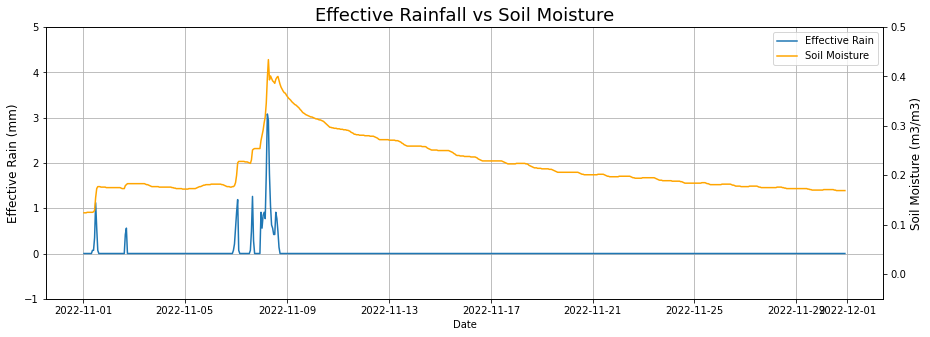

In [4]:
# Plotting rain vs SM

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(111)

line1 = ax.plot(df.index, df.effective_rain, '-', label = 'Effective Rain')
ax2 = ax.twinx()
line2 = ax2.plot(df.index, df.sm, '-', label = 'Soil Moisture', color="orange")

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc=0)

ax.grid()
ax.set_xlabel("Date")
ax.set_ylabel("Effective Rain (mm)", fontsize=12)
ax2.set_ylabel("Soil Moisture (m3/m3)", fontsize=12)
ax2.set_ylim(-0.05, 0.5)
ax.set_ylim(-1, 5)

plt.title('Effective Rainfall vs Soil Moisture', fontsize=18)
plt.show()

Above chart shows the soil moisture following the same trend as rainfall. 
<br>
Rainfall happened in the first 8 days of the month. Soil moisture also had ups and downs in the first 8 days and after that is steadily falling. 

In [5]:
# Calculate daily rain and change in soil moisture

daily_df = df.groupby(df.index.date).agg({'rain': sum, 'effective_rain': sum, 'delta_sm': sum})
daily_df.head()

,rain,effective_rain,delta_sm
2022-11-01,3.2,2.24,0.051
2022-11-02,1.4,0.98,0.008
2022-11-03,0.0,0.00,-0.006
2022-11-04,0.0,0.00,-0.005
2022-11-05,0.0,0.00,0.009


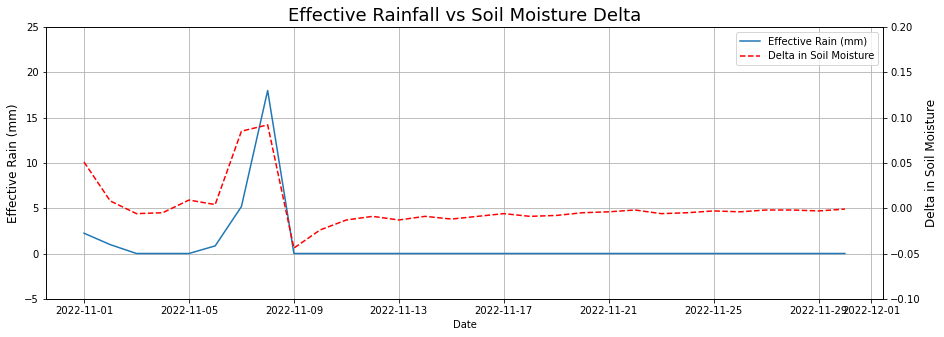

In [6]:
# Plot daily rain vs delta SM

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(111)

line1 = ax.plot(daily_df.index, daily_df.effective_rain, '-', label = 'Effective Rain (mm)')
ax2 = ax.twinx()
line2 = ax2.plot(daily_df.index, daily_df.delta_sm, '--', label = 'Delta in Soil Moisture', color="red")

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc=0)

ax.grid()
ax.set_xlabel("Date")
ax.set_ylabel("Effective Rain (mm)", fontsize=12)
ax2.set_ylabel("Delta in Soil Moisture", fontsize=12)
ax2.set_ylim(-0.1, 0.2)
ax.set_ylim(-5, 25)

plt.title('Effective Rainfall vs Soil Moisture Delta', fontsize=18)
plt.show()

Above chart shows the trend of rainfall and change in soil moisture at a daily level. Here, again we can see that the the delta in SM was positive when there was a rainfall, and negative when there was no rain. 
<br><br>
There is an exception in this trend, though minor: 
- On 5th Nov, there was a slight rise in SM (0.009), though there was no rainfall since past 2 days. <br> This could be because of various reasons such as 
    irrigation, 
    some other form of precipitation like snow, or 
    upward movement of soil water from below 7 cm of soil

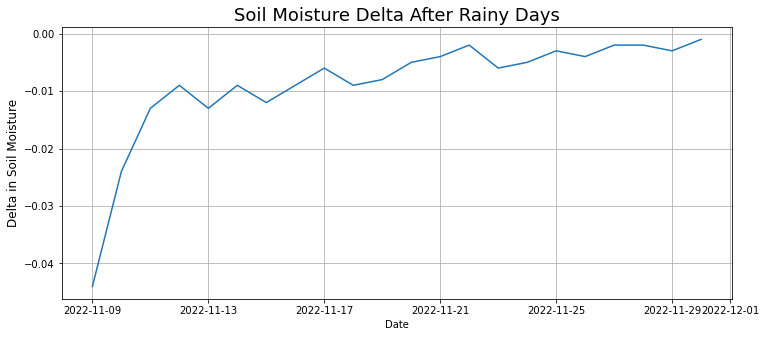

In [7]:
# Plot daily rain vs delta SM

fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(111)

line1 = ax.plot(daily_df[8:].index, daily_df[8:].delta_sm, '-', label = 'Delta in Soil Moisture')
ax.grid()
ax.set_xlabel("Date")
ax.set_ylabel("Delta in Soil Moisture", fontsize=12)

plt.title('Soil Moisture Delta After Rainy Days', fontsize=18)
plt.show()

Starting from 9th Nov, the rate of fall in soil moisture steadily decreases, moving closer to zero. As the soil becomes drier, the rate of moisture loss decreases. 

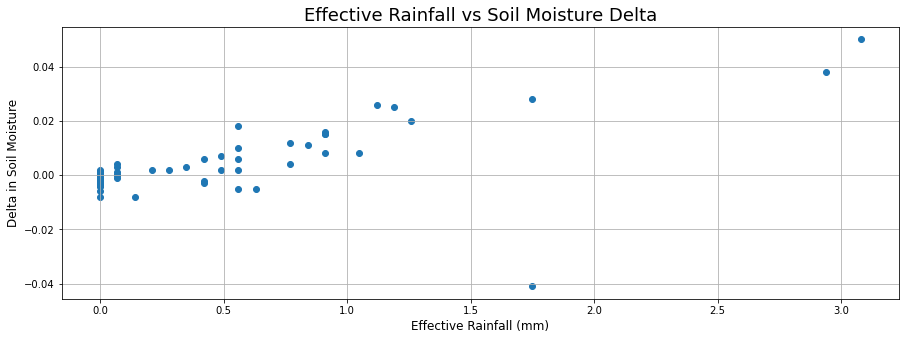

In [8]:
# Plot effective rain vs delta SM

fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(111)
plt.scatter(df.effective_rain, df.delta_sm)

ax.grid()
ax.set_xlabel("Effective Rainfall (mm)", fontsize=12)
ax.set_ylabel("Delta in Soil Moisture", fontsize=12)

plt.title('Effective Rainfall vs Soil Moisture Delta', fontsize=18)
plt.show()

As the depth of rainfall increases, rate of rise in soil moisture also increases. 

In [9]:
print('Day with max rainfall: {}'.format(daily_df.nlargest(1, 'rain').index[0]))
print('Day with max rise in soil moisture: {}'.format(daily_df.nlargest(1, 'delta_sm').index[0]))

Day with max rainfall: 2022-11-08
Day with max rise in soil moisture: 2022-11-08


In [10]:
print('Rainy Days:')
print(daily_df[(daily_df.rain > 0)])

print('Days with rise in SM:')
print(daily_df[daily_df.delta_sm > 0])

Rainy Days:
            rain  effective_rain  delta_sm
2022-11-01   3.2            2.24     0.051
2022-11-02   1.4            0.98     0.008
2022-11-06   1.2            0.84     0.004
2022-11-07   7.4            5.18     0.085
2022-11-08  25.7           17.99     0.092
Days with rise in SM:
            rain  effective_rain  delta_sm
2022-11-01   3.2            2.24     0.051
2022-11-02   1.4            0.98     0.008
2022-11-05   0.0            0.00     0.009
2022-11-06   1.2            0.84     0.004
2022-11-07   7.4            5.18     0.085
2022-11-08  25.7           17.99     0.092


<strong>Since there is no significant increase in soil moisture in the absence of rainfall, we can conclude that the most important factor contributing to soil moisture is rainfall. </strong>